# 03 — A toy model of chemical evolution: the [Mg/Fe] clock

*Lecture 2: chemical evolution*

A **one-zone ("bathtub") model**: gas flows in, stars form, massive stars return enriched gas, a wind blows some gas out.
We follow only magnesium and iron:

* **SN II** (core collapse, $m > 8\,M_\odot$) explode within ~40 Myr: lots of **Mg**, some Fe.
* **SN Ia** (white dwarfs in binaries) explode with a delay-time distribution $\propto 1/t$ after ~40 Myr: mostly **Fe**.

Notation: $[X/H] = \log_{10}(X/H) - \log_{10}(X/H)_\odot$ and $[\mathrm{Mg/Fe}] = [\mathrm{Mg/H}] - [\mathrm{Fe/H}]$.

The code is in `stellarpops/toy_gce.py` — about 100 lines, read it! The yields are illustrative; for real models see notebook 04 (galevo).

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))   # makes the small 'stellarpops' package importable
import numpy as np
import matplotlib.pyplot as plt
from stellarpops.style import use_slide_style
use_slide_style(dark=False, scale=0.7)       # dark=True gives the lecture-slide look

from stellarpops import run_one_zone

## 1. A Milky-Way-like disc

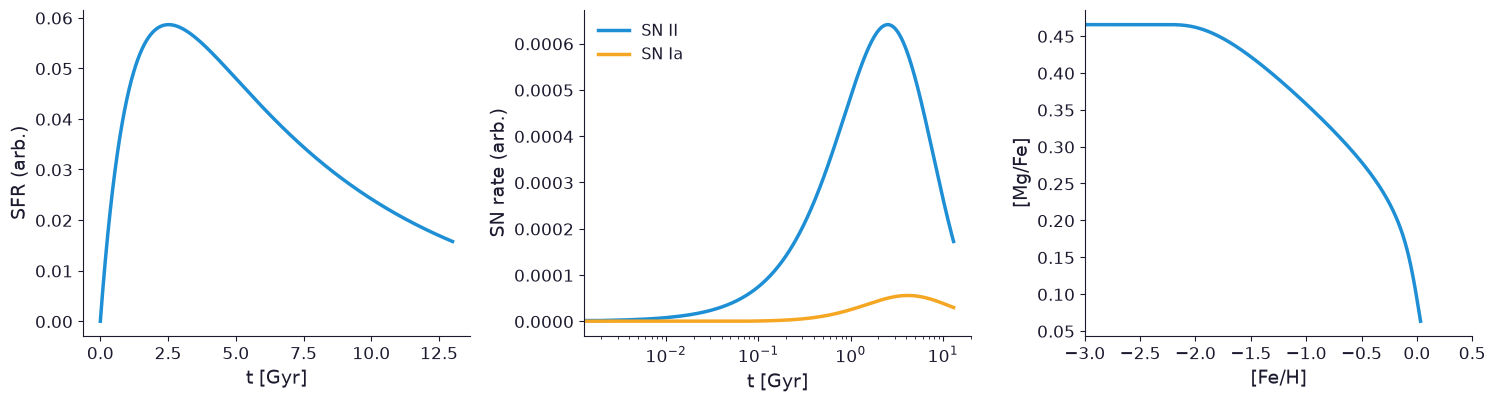

In [2]:
r = run_one_zone(tau_sf=2.0, infall_tau=7.0, eta=1.0)
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
axs[0].plot(r['t'], r['sfr']); axs[0].set_xlabel('t [Gyr]'); axs[0].set_ylabel('SFR (arb.)')
axs[1].plot(r['t'], r['rate_ii'], label='SN II'); axs[1].plot(r['t'], r['rate_ia'], label='SN Ia')
axs[1].set_xscale('log'); axs[1].set_xlabel('t [Gyr]'); axs[1].set_ylabel('SN rate (arb.)'); axs[1].legend()
axs[2].plot(r['FeH'], r['MgFe']); axs[2].set_xlim(-3, 0.5); axs[2].set_xlabel('[Fe/H]'); axs[2].set_ylabel('[Mg/Fe]')
plt.tight_layout()

**Questions:** where is the *plateau* and what sets its height? Where is the *knee* and what happens there?

## 2. Fast vs slow star formation

elliptical: fast, quenched at 0.5 Gyr    mass-weighted stellar [Fe/H] = -0.35, [Mg/Fe] = +0.35
Milky-Way-like disc                      mass-weighted stellar [Fe/H] = -0.18, [Mg/Fe] = +0.17
dwarf: slow and leaky                    mass-weighted stellar [Fe/H] = -0.96, [Mg/Fe] = +0.16


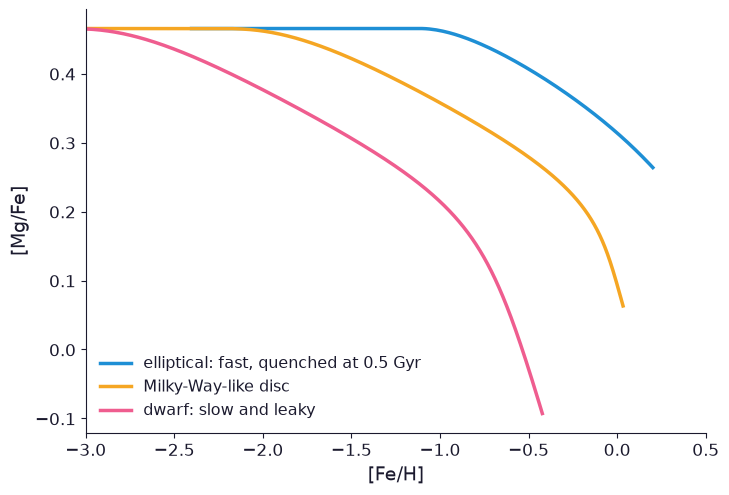

In [3]:
models = {'elliptical: fast, quenched at 0.5 Gyr': dict(tau_sf=0.3, t_stop=0.5, eta=0.5),
          'Milky-Way-like disc': dict(tau_sf=2.0, infall_tau=7.0, eta=1.0),
          'dwarf: slow and leaky': dict(tau_sf=15.0, infall_tau=3.0, eta=10.0)}
plt.figure(figsize=(8, 5.5))
for name, p in models.items():
    r = run_one_zone(**p)
    act = r['sfr'] > 0                  # only while stars still form
    plt.plot(r['FeH'][act], r['MgFe'][act], label=name)
    print(f"{name:40s} mass-weighted stellar [Fe/H] = {r['star_FeH'][-1]:+.2f}, [Mg/Fe] = {r['star_MgFe'][-1]:+.2f}")
plt.xlim(-3, 0.5); plt.xlabel('[Fe/H]'); plt.ylabel('[Mg/Fe]'); plt.legend()

**Your turn:** find a star-formation time scale `tau_sf` and quenching time `t_stop` that give a mass-weighted stellar [Mg/Fe] ≈ +0.3 (a massive elliptical, Thomas et al. 2005). How short must star formation be?

In [4]:
# your code here

## 3. The IMF moves the plateau
`alpha_high` is the IMF slope above 1 M$_\odot$ (Kroupa = 2.3). More massive SN II progenitors produce more Mg per Fe.

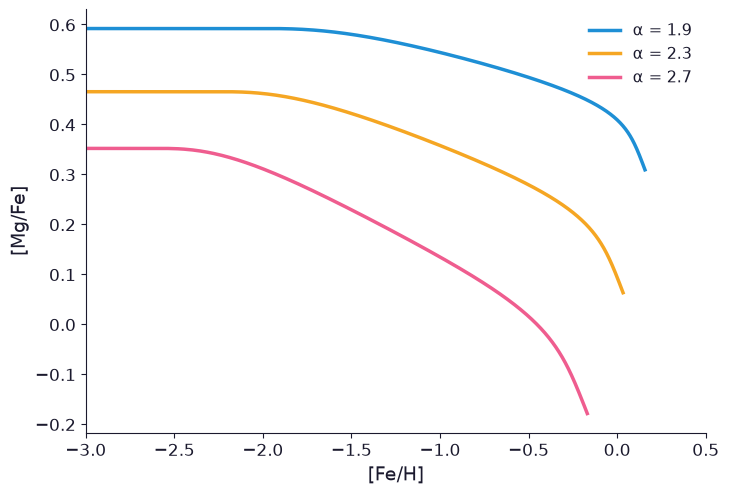

In [5]:
plt.figure(figsize=(8, 5.5))
for a in [1.9, 2.3, 2.7]:
    r = run_one_zone(tau_sf=2.0, infall_tau=7.0, eta=1.0, alpha_high=a)
    plt.plot(r['FeH'], r['MgFe'], label=f'α = {a}')
plt.xlim(-3, 0.5); plt.xlabel('[Fe/H]'); plt.ylabel('[Mg/Fe]'); plt.legend()

**The degeneracy:** a high [Mg/Fe] can mean *fast* star formation **or** a *top-heavy* IMF. How could you tell them apart? (Hints: metallicity, other elements, the mass-to-light ratio from notebook 02.)

## 4. Galaxy chef: the cosmic-kitchen game, now with orders to fill
In the lecture you played one recipe on paper. Here you are the chef and the customers are picky.

**Kitchen rules (same as on paper):** you have **8 units** of star formation to spend over **8 rounds** (1 round ≈ 250 Myr).
Each unit makes **3 Mg + 1 Fe at once** (SN II) and books SN Ia iron for later: **+1 Fe** one round later, **+1** two rounds later, **+1** four rounds later.
The stars formed in a round get the [Mg/Fe] of the pot at that moment, so what the customer receives is the mass-weighted [Mg/Fe] of all your stars.

Run the next cell once, then try to fill the four orders below (the recipes given are starting guesses that fail). One order is impossible in this kitchen: find out which and **why**. In class: first team to fill A–C wins; lowest [Mg/Fe] for order B goes on the board.

In [6]:
def kitchen(recipe, mg_per_unit=3, rounds=8, show=True):
    """Play a recipe = list of star-formation units per round. Returns the stars' mass-weighted [Mg/Fe]."""
    recipe = list(recipe) + [0] * (rounds - len(recipe))
    mg = fe = 0.0
    due = np.zeros(rounds + 10)
    star_units, star_ratio = [], []
    if show:
        print('round  units   Mg    Fe   pot [Mg/Fe]')
    for r in range(rounds):
        fe += due[r]                         # 1. SN Ia deliveries
        u = recipe[r]
        mg += mg_per_unit * u; fe += u       # 2. form stars -> SN II at once
        for delay in (1, 2, 4):              #    ... and book their SN Ia
            due[r + delay] += u
        ratio = mg / fe if fe > 0 else np.nan
        if u > 0:
            star_units.append(u); star_ratio.append(ratio)
        if show:
            print(f'{r+1:5d} {u:6d} {mg:5.0f} {fe:5.0f}   {np.log10(ratio):+.2f}' if fe > 0 else f'{r+1:5d} {u:6d}   (empty pot)')
    if not star_units:
        return np.nan
    stars = np.log10(np.average(star_ratio, weights=star_units))
    if show:
        print(f'-> your stars: [Mg/Fe] = {stars:+.2f}')
    return stars


ORDERS = {
    'A. Giant elliptical': ('all 8 units used, stars [Mg/Fe] >= +0.42',
                            lambda rec, x: sum(rec) == 8 and x >= 0.42),
    'B. Milky-Way disc':   ('all 8 units, star formation in at least 6 rounds, stars [Mg/Fe] <= +0.17 (the steady 1-per-round recipe gives +0.18: beat it)',
                            lambda rec, x: sum(rec) == 8 and sum(u > 0 for u in rec) >= 6 and x <= 0.17),
    'C. Iron-rich today':  ('all 8 units, some stars form in round 8, and those round-8 stars have [Mg/Fe] <= 0',
                            None),   # checked below: needs the pot of round 8
    'D. Super-alpha':      ('all 8 units used, stars [Mg/Fe] >= +0.55',
                            lambda rec, x: sum(rec) == 8 and x >= 0.55),
}


def serve(order, recipe, mg_per_unit=3):
    rec = list(recipe) + [0] * (8 - len(recipe))
    text, check = ORDERS[order]
    print(f'ORDER {order}: {text}')
    x = kitchen(rec, mg_per_unit=mg_per_unit)
    if check is None:     # order C: look at the pot when the round-8 stars form
        mg = fe = 0.0; due = np.zeros(20)
        for r in range(8):
            fe += due[r]; mg += mg_per_unit * rec[r]; fe += rec[r]
            for d in (1, 2, 4): due[r + d] += rec[r]
        ok = sum(rec) == 8 and rec[7] > 0 and np.log10(mg / fe) <= 0
    else:
        ok = check(rec, x)
    print('ORDER FILLED ✅' if ok else 'Customer sends it back ❌  - try again')


for name, (text, _) in ORDERS.items():
    print(f'{name}: {text}')

A. Giant elliptical: all 8 units used, stars [Mg/Fe] >= +0.42
B. Milky-Way disc: all 8 units, star formation in at least 6 rounds, stars [Mg/Fe] <= +0.17 (the steady 1-per-round recipe gives +0.18: beat it)
C. Iron-rich today: all 8 units, some stars form in round 8, and those round-8 stars have [Mg/Fe] <= 0
D. Super-alpha: all 8 units used, stars [Mg/Fe] >= +0.55


In [7]:
# Your turn: change the recipes until every order you think is possible is filled.
serve('A. Giant elliptical', [4, 4, 0, 0, 0, 0, 0, 0])

ORDER A. Giant elliptical: all 8 units used, stars [Mg/Fe] >= +0.42
round  units   Mg    Fe   pot [Mg/Fe]
    1      4    12     4   +0.48
    2      4    24    12   +0.30
    3      0    24    20   +0.08
    4      0    24    24   +0.00
    5      0    24    28   -0.07
    6      0    24    32   -0.12
    7      0    24    32   -0.12
    8      0    24    32   -0.12
-> your stars: [Mg/Fe] = +0.40
Customer sends it back ❌  - try again


In [8]:
serve('B. Milky-Way disc', [1, 1, 1, 1, 1, 1, 1, 1])

ORDER B. Milky-Way disc: all 8 units, star formation in at least 6 rounds, stars [Mg/Fe] <= +0.17 (the steady 1-per-round recipe gives +0.18: beat it)
round  units   Mg    Fe   pot [Mg/Fe]
    1      1     3     1   +0.48
    2      1     6     3   +0.30
    3      1     9     6   +0.18
    4      1    12     9   +0.12
    5      1    15    13   +0.06
    6      1    18    17   +0.02
    7      1    21    21   +0.00
    8      1    24    25   -0.02
-> your stars: [Mg/Fe] = +0.18
Customer sends it back ❌  - try again


In [9]:
serve('C. Iron-rich today', [0, 0, 0, 0, 0, 0, 0, 8])

ORDER C. Iron-rich today: all 8 units, some stars form in round 8, and those round-8 stars have [Mg/Fe] <= 0
round  units   Mg    Fe   pot [Mg/Fe]
    1      0   (empty pot)
    2      0   (empty pot)
    3      0   (empty pot)
    4      0   (empty pot)
    5      0   (empty pot)
    6      0   (empty pot)
    7      0   (empty pot)
    8      8    24     8   +0.48
-> your stars: [Mg/Fe] = +0.48
Customer sends it back ❌  - try again


**Order D.** Try any recipe you like for the super-alpha galaxy. When you are convinced it cannot be done with this kitchen, explain why in one sentence — what sets the ceiling?

Then change the *kitchen*, not the recipe: a top-heavy IMF means more very massive SN II, i.e. more Mg per unit. Try `serve('D. Super-alpha', your_recipe, mg_per_unit=4)`.
This is the degeneracy from the lecture: a high [Mg/Fe] can mean *fast* star formation **or** a *top-heavy* IMF.

**Order C:** why does putting all 8 units into round 8 fail, even though that is the latest possible moment? What do you need to do earlier, and why?

In [10]:
serve('D. Super-alpha', [8], mg_per_unit=3)

ORDER D. Super-alpha: all 8 units used, stars [Mg/Fe] >= +0.55
round  units   Mg    Fe   pot [Mg/Fe]
    1      8    24     8   +0.48
    2      0    24    16   +0.18
    3      0    24    24   +0.00
    4      0    24    24   +0.00
    5      0    24    32   -0.12
    6      0    24    32   -0.12
    7      0    24    32   -0.12
    8      0    24    32   -0.12
-> your stars: [Mg/Fe] = +0.48
Customer sends it back ❌  - try again
